# 위임 구조 실습: 요청 수 셈으로 호출 한도를 정하고 완료 조건으로 확인하기

**이 노트북에서 할 일**

1. 01절 요청 수 셈, 04절 호출 한도, 04절 완료 조건을 자료실 문의 창구 흐름 하나에 모읍니다.
2. 셈으로 정한 호출 한도 2를 붙여 문의 하나를 처리하고, 일이 끝났는지 완료 조건으로 봅니다.
3. 호출 한도 하나만 1로 줄여 다시 처리하고, 두 실행을 견줍니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 모델 요청은 6절에서 3번, 7절에서 2번, 모두 5번입니다.
요금표로 어림한 예상 비용은 두 실행을 합쳐 0.002달러 아래이고, 청구 금액이 아닙니다.
맡기는 모양과 답 글, 토큰 수는 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.

읽거나 쓰는 파일은 없고, 체크포인터도 쓰지 않습니다.
앞에서 배운 함수 다섯은 도구 파일 `delegation_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 넷을 설치합니다.
판은 langchain 1.4.0과 langchain-openai 1.6.0입니다.
langgraph 1.2.11과 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**실습 범위** — 이 절은 챕터 끝 실습 절이고 30분 안에 끝나는 분량입니다.
강사와 함께 첫 셀부터 차례로 실행하고, 따로 내는 과제는 없습니다.
01~04절에서 쓴 이름과 Ch 2에서 배운 문법만 씁니다.
실행 셀 하나만 다시 실행하면 모델 요청이 더 나가고, 토큰 수가 달라질 수 있습니다.

실습 폴더 `labs/part6/ch26-delegation`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 초록 상자 둘, 문의 글 한 줄 대출 연장 필요한 분야 loan_desk와 호출 한도 값 실행 1은 2 실행 2는 1에서 화살표가 파란 상자 조립 함수 handle_inquiry 04절 호출 한도를 붙여 04절 중앙 에이전트를 만듦으로 모입니다. 그 아래 회색 상자 중앙 에이전트 도구 ask_desk_agent 하나 01절 서브에이전트 모양에서, 도구로 맡김이라고 적힌 화살표가 오른쪽 아래 회색 상자 전문 에이전트 loan_desk 03절 desk_agents 도구 없음으로 갑니다. 중앙 에이전트에서 바깥 목록, 전문 에이전트에서 안쪽 목록이라고 적힌 화살표가 파란 상자 기록 장치 summarize_run 01절 요청 수 셈 04절 완료 조건으로 모이고, 맨 아래 노란 상자 출력 모인 분야 마지막 답 모델 요청 수 완료 조건으로 이어지는 그림](attachment:05-1-셈으로-정한-호출-한도를-붙인-창구.png)

위에서 아래로 읽습니다.
초록 상자 둘은 실행 전에 정한 값이고, 호출 한도 값만 두 실행에서 다릅니다.
파란 상자는 이 노트북에 적은 함수이고, 회색 상자는 create_agent로 만든 에이전트입니다.
기록 장치는 바깥 목록과 안쪽 목록을 함께 읽어 요청 수를 세고, 완료 조건을 봅니다.
이 그림에는 실행 결과의 값을 넣지 않았습니다.
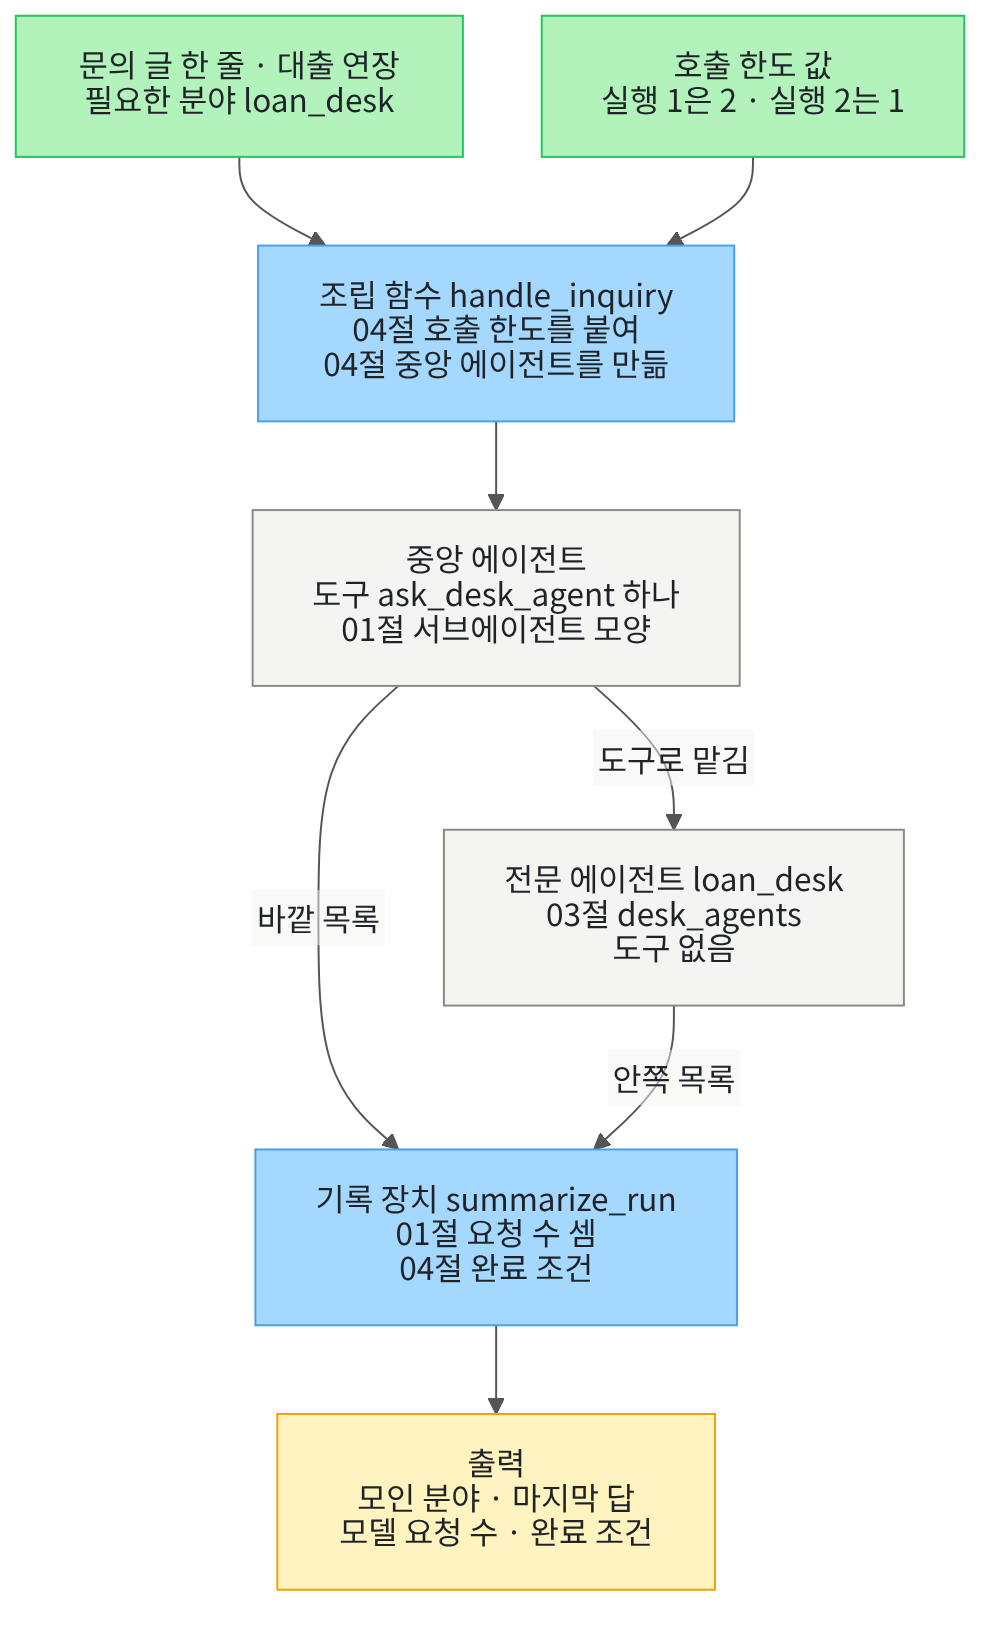

## 1. 준비

이번 절은 이 챕터의 실습입니다.
01절 요청 수 셈, 04절 호출 한도, 04절 완료 조건을 문의 창구 흐름 하나에 모읍니다.
첫 셀은 01절과 같은 패키지 넷을 설치하고, 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`과 `langgraph: 1.2.11`이 보입니다.
네 판 모두 실습 폴더 잠금과 같은 판입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
에이전트를 만드는 함수 `create_agent`는 Ch 21 01절에서 썼습니다.
호출 한도 `ModelCallLimitMiddleware`는 Ch 22 04절에서 썼고, 04절 7절에서도 붙여 보았습니다.
마지막 가져오기 줄은 앞에서 배운 함수 다섯을 도구 파일에서 가져옵니다.
이 절에서 새로 배우는 이름은 없습니다.

In [2]:
# 에이전트와 호출 한도(Ch 21 01절·Ch 22 04절)·모델(Ch 6 01절)·메시지(Ch 13 04절)·도구(Ch 19 01절) 이름을 가져옵니다
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain.tools import tool
# 앞 절에서 배운 함수 넷과 앞 챕터에서 배운 함수 하나는 도구 파일에서 가져옵니다
from delegation_tools import answered_desks, estimate_cost, is_complete, message_kinds, usage_with_specialists

print("도구 파일에서 가져온 함수:", "answered_desks, estimate_cost, is_complete, message_kinds, usage_with_specialists")

도구 파일에서 가져온 함수: answered_desks, estimate_cost, is_complete, message_kinds, usage_with_specialists


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: answered_desks, estimate_cost, is_complete, message_kinds, usage_with_specialists`가 보입니다.
함수 `message_kinds`·`usage_with_specialists`는 01절 노트북 4·5절에서 처음 적었습니다.
함수 `answered_desks`·`is_complete`는 04절 노트북 3·8절에서 처음 적었습니다.
함수 `estimate_cost`는 Ch 6 06절 함수입니다.

04절 함수 둘은 이 절에서 도구 파일로 옮겼고, 설명 주석과 본문은 04절 셀 글 그대로입니다.
인자도 04절 셀과 같아, 04절에서 부른 모양 그대로 부르면 됩니다.

앞에서 배운 함수는 `delegation_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
중앙 에이전트와 전문 에이전트가 모두 이 모델 객체 하나를 함께 씁니다.

## 2. 오늘 처리할 문의

자료실 문의 창구에 이용자의 문의가 하나 들어왔다고 합시다.
창구의 중앙 에이전트는 문의를 담당에게 맡기고, 받은 답으로 최종 답을 씁니다.
그런데 모델이 도구를 끝없이 부르면, 요청과 요금도 끝없이 늘어납니다.
그래서 이번 실습은 중앙 에이전트에 호출 한도를 붙이고, 일이 끝났는지 따로 확인합니다.
다음 셀은 오늘 처리할 문의 글과 필요한 분야를 정하고, 출처와 함께 출력합니다.

In [5]:
# 두 실행에 보낼 문의 글과, 완료 조건에 쓸 필요한 분야를 실행 전에 정하고 출처와 함께 출력합니다
question_text = "빌린 책의 반납 날짜를 늘리려면 어떻게 하나요?"
needed_desks = ["loan_desk"]
print("문의 글:", question_text)
print("출처: 01절 문의 글 그대로")
print("필요한 분야:", needed_desks)
print("출처: 문의 글이 묻는 것은 대출 연장 하나")

문의 글: 빌린 책의 반납 날짜를 늘리려면 어떻게 하나요?
출처: 01절 문의 글 그대로
필요한 분야: ['loan_desk']
출처: 문의 글이 묻는 것은 대출 연장 하나


**결과 읽기** — 출력 줄 `문의 글: 빌린 책의 반납 날짜를 늘리려면 어떻게 하나요?`가 보입니다.
문의 글은 01절 문의 글 그대로이고, 대출 연장 하나만 묻습니다.
그래서 출력 줄 `필요한 분야: ['loan_desk']`처럼, 필요한 분야를 대출 규정 담당 하나로 정했습니다.
두 값은 실행 전에 정했고, 결과를 보고 바꾸지 않았습니다.

## 3. 재료 만들기

재료는 04절과 같은 분야 이름, 규정 글, 전문 에이전트, 도구입니다.
먼저 분야 이름 셋과 세 담당의 교재용 규정 글을 정합니다.

In [6]:
# 분야 이름 셋과 세 담당의 교재용 규정 글을 정합니다(대출은 01절, 상호대차는 02절, 시설은 03절 글 그대로)
desk_names = ["loan_desk", "interlibrary_desk", "facility_desk"]
loan_rules = "[교재용 대출·반납 규정] 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다. 반납 예정일 전에 한 번, 7일 연장할 수 있습니다."
loan_rules = loan_rules + " 예약한 사람이 있는 책은 연장할 수 없습니다. 연체한 일수만큼 새 대출이 제한됩니다."
interlibrary_rules = "[교재용 상호대차 규정] 다른 도서관의 책은 자료실 창구에서 상호대차로 신청합니다."
interlibrary_rules = interlibrary_rules + " 신청한 책은 보통 3~5일 뒤에 도착합니다."
interlibrary_rules = interlibrary_rules + " 책이 도착하면 문자로 알리고, 7일 안에 찾아가야 합니다."
facility_rules = "[교재용 시설 규정] 자료실은 평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다."
print("분야 이름:", desk_names)

분야 이름: ['loan_desk', 'interlibrary_desk', 'facility_desk']


**결과 읽기** — 출력 줄 `분야 이름: ['loan_desk', 'interlibrary_desk', 'facility_desk']`가 보입니다.
분야 이름과 세 규정 글은 04절 2절 셀과 같습니다.
규정 글은 모두 교재용으로 만든 글이라 실제 도서관 규정이 아닙니다.

다음 셀은 03절 5절 셀과 같은 코드로, 도구 없는 전문 에이전트 셋을 만듭니다.

In [7]:
# 세 규정 글로 도구 없는 전문 에이전트 셋을 만들고, 분야 이름으로 찾을 수 있게 딕셔너리에 담습니다
answer_rule = " 문의 가운데 아래 교재용 규정에 해당하는 부분에만 한 문장의 한국어로 답하세요.\n"
loan_text = "도서관 자료실의 대출 규정 담당입니다." + answer_rule + loan_rules
interlibrary_text = "도서관 자료실의 상호대차 담당입니다." + answer_rule + interlibrary_rules
facility_text = "도서관 자료실의 시설 담당입니다." + answer_rule + facility_rules
desk_agents = {}
desk_agents["loan_desk"] = create_agent(model, tools=[], system_prompt=loan_text, name="loan_desk")
desk_agents["interlibrary_desk"] = create_agent(model, tools=[], system_prompt=interlibrary_text, name="interlibrary_desk")
desk_agents["facility_desk"] = create_agent(model, tools=[], system_prompt=facility_text, name="facility_desk")
print("전문 에이전트:", list(desk_agents))

전문 에이전트: ['loan_desk', 'interlibrary_desk', 'facility_desk']


**결과 읽기** — 출력 줄 `전문 에이전트: ['loan_desk', 'interlibrary_desk', 'facility_desk']`가 보입니다.
01절에서 본 것처럼, 도구 없는 전문 에이전트는 한 번 부르면 모델 요청이 1번입니다.

다음 셀은 04절 3절과 같은 도구입니다.
분야 이름을 받아 그 담당에게 넘긴 글을 맡기고, 담당의 마지막 답 글을 내놓습니다.
담당이 받고 쓴 메시지 목록인 안쪽 목록은 기록 목록 `specialist_runs`에 붙습니다.

In [8]:
# 분야 이름과 넘길 글을 받아 그 분야 담당에게 맡기고, 담당의 마지막 답 글을 내놓는 도구 하나입니다
@tool
def ask_desk_agent(desk: str, question: str):
    """문의 가운데 한 분야 부분을 그 분야 담당(loan_desk·interlibrary_desk·facility_desk)에게 맡기고, 담당의 답 글을 받습니다."""
    # 분야 이름으로 담당을 찾고, 담당은 넘긴 글 한 줄만 든 새 메시지 목록으로 일합니다(01절 도구와 같은 모양)
    agent = desk_agents[desk]
    inner_input = {"messages": [HumanMessage(content=question)]}
    inner_result = agent.invoke(inner_input)
    specialist_runs.append(inner_result["messages"])
    return inner_result["messages"][-1].text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
줄 `@tool`은 01절 3절에서 본 것처럼 아래 함수를 도구로 등록합니다.
기록 목록 `specialist_runs`는 실행 셀마다 빈 목록으로 새로 만듭니다.

다음 셀은 04절 3절과 같은 담당 설명 글과 중앙 에이전트의 시스템 메시지 글을 정합니다.
중앙 에이전트는 호출 한도를 붙여 만들어야 하므로, 이 셀이 아니라 5절 조립 함수에서 만듭니다.
모델이 도는 에이전트에 줄 실행 한도도 이 셀에서 정합니다.

In [9]:
# 04절 3절과 같은 담당 설명 글과 중앙 에이전트의 시스템 메시지 글, 에이전트에 줄 실행 한도를 정합니다
desk_guide = " loan_desk는 대출·반납·연장·연체, interlibrary_desk는 다른 도서관 책을 빌려 오는 상호대차를 맡습니다."
desk_guide = desk_guide + " facility_desk는 자료실 운영 시간과 시설을 맡습니다."
central_text = "도서관 자료실 문의 창구의 안내 도우미입니다. 규정을 묻는 부분은 직접 답하지 말고 ask_desk_agent 도구로 담당에게 맡기세요."
central_text = central_text + desk_guide + " 담당이 준 답을 바탕으로 두 문장의 한국어로 답하세요."
# 모델이 끝없이 도구를 부르면 요청도 끝없이 나가므로, 실행 한도를 작게 줍니다(Ch 20 03절)
limit_config = {"recursion_limit": 10}
print("도구 인자:", list(ask_desk_agent.args))

도구 인자: ['desk', 'question']


**결과 읽기** — 출력 줄 `도구 인자: ['desk', 'question']`이 보입니다.
중앙 에이전트의 모델은 이 두 인자를 채워 도구를 요청합니다.
04절 7절에서 본 것처럼, 실행 한도는 그래프의 단계 수를 세고 호출 한도는 모델 요청 수를 셉니다.
실행 한도 10은 두 실행에 같게 주는 값입니다.

## 4. 결과를 볼 기록 장치

실행이 끝난 뒤 일이 끝났는지 보려면, 실행 기록을 읽어 값을 모으는 장치가 있어야 합니다.
먼저 모델 요청 수를 세는 함수입니다.
01절 함수 `usage_with_specialists`는 바깥 목록의 새 메시지와 안쪽 목록의 응답을 함께 셉니다.
그런데 호출 한도가 적어 넣은 응답은 모델 요청이 아니어서, 사용량이 `None`입니다.
01절 6절에서 본 것처럼, 사용량이 `None`인 응답을 넘기면 토큰 수를 꺼내다 멈춥니다.

In [10]:
# 이번 실행의 모델 요청 수와 토큰을 셉니다. 호출 한도가 적어 넣은 마지막 응답(사용량 None)은 빼고 셉니다
def count_run_usage(new_messages, inner_runs):
    counted = new_messages
    if new_messages[-1].usage_metadata is None:
        # 자르기 [:-1]은 맨 끝 하나를 뺀 앞부분입니다
        counted = new_messages[:-1]
    # 바깥 목록의 새 메시지와 안쪽 목록의 응답을 함께 셉니다(01절 함수)
    return usage_with_specialists(counted, inner_runs)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
마지막 응답의 사용량이 `None`이면, 자르기 `[:-1]`로 그 응답만 빼고 셉니다.
자리 `-1`이 맨 끝 자리이니, `[:-1]`은 맨 끝 하나를 뺀 앞부분입니다.

다음 셀은 한 번의 실행에서 모인 분야, 마지막 답, 요청 수, 완료 조건을 모으는 함수입니다.
모인 분야는 04절 함수 `answered_desks`로, 완료 조건은 04절 함수 `is_complete`로 봅니다.
마지막 답이 있는지는 04절 3절과 같은 식으로, 마지막 응답의 사용량과 도구 요청을 봅니다.

In [11]:
# 기록 장치입니다. 한 번의 실행에서 모인 분야·마지막 답·모델 요청 수·완료 조건을 모아 딕셔너리로 내놓습니다
def summarize_run(new_messages, inner_runs, needed):
    collected = answered_desks(inner_runs, desk_names)
    last = new_messages[-1]
    # 모델 요청으로 받은 응답에는 사용량 기록이 있습니다(04절 3절과 같은 판단)
    has_final = last.usage_metadata is not None and len(last.tool_calls) == 0
    usage = count_run_usage(new_messages, inner_runs)
    done = is_complete(collected, needed, has_final)
    return {"collected": collected, "final": has_final, "usage": usage, "complete": done}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 안에서 앞 셀의 `count_run_usage`를 부르므로, 앞 셀을 먼저 실행해 두어야 합니다.
토큰 수는 딕셔너리의 키 `usage` 안에 함께 담기고, 8절에서만 출력합니다.

## 5. 조립

이제 앞 절의 기능을 조립 함수 하나로 붙입니다.
조립 함수는 호출 한도 값과 문의 글을 받아, 한도를 붙인 중앙 에이전트를 만들고 문의를 맡깁니다.
호출 한도에는 04절 7절처럼 `exit_behavior="end"`를 주어, 한도에 닿으면 오류 없이 끝나게 합니다.
중앙 에이전트는 04절 3절과 같은 도구와 시스템 메시지 글로 만듭니다.
조립 함수는 이번 실행이 더한 바깥 메시지만 잘라 내놓습니다.

In [12]:
# 조립 함수입니다. 호출 한도를 붙인 중앙 에이전트를 만들어 문의 하나를 맡기고, 이번 실행이 더한 바깥 메시지를 내놓습니다
def handle_inquiry(limit, question):
    # 04절 7절: 한 번 실행 안에서 보낼 수 있는 모델 요청 수를 limit으로 묶고, 닿으면 끝으로 갑니다
    call_limit = ModelCallLimitMiddleware(run_limit=limit, exit_behavior="end")
    # 04절 3절: 분야 이름을 받는 도구 하나를 가진 중앙 에이전트(01절 서브에이전트 모양)
    center = create_agent(model, tools=[ask_desk_agent], system_prompt=central_text, middleware=[call_limit])
    center_input = {"messages": [HumanMessage(content=question)]}
    center_result = center.invoke(center_input, limit_config)
    return center_result["messages"][1:]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 안 주석에 각 줄이 어느 절에서 배운 것인지 적었습니다.
중앙 에이전트를 실행할 때 실행 한도 `limit_config`도 함께 줍니다.

다음 셀은 실행 1에 줄 호출 한도를 01절 셈으로 정합니다.
01절에서 본 셈대로, 중앙 에이전트의 요청 수는 도구를 요청한 응답 수 + 1입니다.
한 분야 문의를 한 번 맡기면, 중앙 요청은 도구를 요청한 응답 1번과 최종 답 1번입니다.

In [13]:
# 실행 1의 호출 한도를 01절 셈으로 정합니다. 한 번 맡기면 중앙 요청은 도구를 요청한 응답 1 + 최종 답 1입니다
tool_responses = 1
first_limit = tool_responses + 1
print("실행 1의 호출 한도:", first_limit)
print("출처: 01절 셈 중앙 = 도구를 요청한 응답 수 + 1")

실행 1의 호출 한도: 2
출처: 01절 셈 중앙 = 도구를 요청한 응답 수 + 1


**결과 읽기** — 출력 줄 `실행 1의 호출 한도: 2`가 보입니다.
이 값은 실행 전에 셈으로 정했고, 결과를 보고 바꾸지 않았습니다.
04절 7절에서 본 대로, 호출 한도는 한도를 붙인 중앙 에이전트의 요청만 셉니다.
그래서 담당의 요청은 한도 값에 넣지 않았습니다.

## 6. 실행 1 · 호출 한도 2

실행 1은 셈으로 정한 호출 한도 2를 붙여 문의를 처리합니다.
실행 전에 예상해 봅니다.
중앙 에이전트가 담당에게 한 번 맡기면, 한도에 닿기 전에 최종 답까지 쓸 것입니다.
그러면 모델 요청은 중앙 2번과 담당 1번으로 3번일 것입니다.

In [14]:
# 실행 1: 기록 목록을 비우고, 호출 한도 2를 붙인 중앙 에이전트로 문의를 처리합니다(모델 요청 3번 예상)
specialist_runs = []
first_new = handle_inquiry(first_limit, question_text)
print("이번 실행이 더한 바깥 메시지:", message_kinds(first_new))
print("전문 에이전트를 부른 횟수:", len(specialist_runs))

이번 실행이 더한 바깥 메시지: ['AIMessage', 'ToolMessage', 'AIMessage']
전문 에이전트를 부른 횟수: 1


**결과 읽기** — 출력 줄 `이번 실행이 더한 바깥 메시지: ['AIMessage', 'ToolMessage', 'AIMessage']`가 보입니다.
응답 하나 뒤에 도구 메시지 하나가 오고, 마지막에 응답이 하나 더 있습니다.
출력 줄 `전문 에이전트를 부른 횟수: 1`로 담당이 한 번 불렸습니다.

맡기는 모양은 모델이 정해 실행마다 달라질 수 있습니다.
노트북 밖에서 같은 실행을 다섯 번 보냈을 때는 다섯 번 모두 첫 응답에서 한 번 맡겼습니다.

다음 셀은 중앙 에이전트 첫 응답의 도구 요청과, 담당의 안쪽 목록을 봅니다.

In [15]:
# 실행 1에서 중앙 에이전트 첫 응답의 도구 요청과, 담당의 안쪽 목록 줄 수를 봅니다
first_calls = first_new[0].tool_calls
print("첫 응답의 도구 요청 수:", len(first_calls))
print("도구 인자의 분야 이름:", first_calls[0]["args"]["desk"])
print("안쪽 목록의 줄 수:", len(specialist_runs[0]))

첫 응답의 도구 요청 수: 1
도구 인자의 분야 이름: loan_desk
안쪽 목록의 줄 수: 2


**결과 읽기** — 출력 줄 `첫 응답의 도구 요청 수: 1`과 `도구 인자의 분야 이름: loan_desk`가 보입니다.
중앙 에이전트의 모델이 도구 인자에 대출 규정 담당의 이름을 적었습니다.
출력 줄 `안쪽 목록의 줄 수: 2`는 01절에서 본 것처럼, 넘긴 글 한 줄과 담당의 답 한 줄입니다.

다음 셀은 앞에서 만든 기록 장치로 실행 1을 모읍니다.

In [16]:
# 실행 1을 기록 장치로 모아, 모인 분야·마지막 답·모델 요청 수·완료 조건을 봅니다
first_summary = summarize_run(first_new, specialist_runs, needed_desks)
print("담당 답이 모인 분야:", first_summary["collected"])
print("마지막 응답이 도구 요청 없는 모델 응답인가:", first_summary["final"])
print("모델 요청 수(중앙 + 전문):", first_summary["usage"]["requests"])
print("완료 조건:", first_summary["complete"])

담당 답이 모인 분야: ['loan_desk']
마지막 응답이 도구 요청 없는 모델 응답인가: True
모델 요청 수(중앙 + 전문): 3
완료 조건: True


**결과 읽기** — 출력 줄 `담당 답이 모인 분야: ['loan_desk']`와 `마지막 응답이 도구 요청 없는 모델 응답인가: True`가 보입니다.
출력 줄 `모델 요청 수(중앙 + 전문): 3`은 예상대로 중앙 2번과 담당 1번입니다.
출력 줄 `완료 조건: True`로, 필요한 분야의 답이 모였고 최종 답도 있습니다.
호출 한도는 모델 요청 전에 센 수를 보므로, 둘째 요청 전의 수 1은 한도 2에 닿지 않았습니다.
이 실행은 중앙 에이전트의 모델이 도구 요청 없는 응답을 골라 끝났습니다.

## 7. 실행 2 · 호출 한도 1

값 하나만 바꿔 봅니다.
바꿀 값은 호출 한도이고, 2를 1로 줄입니다.
문의 글, 필요한 분야, 도구, 시스템 메시지 글, 실행 한도는 실행 1과 같습니다.
실행 전에 예상해 봅니다.
첫 요청에서 담당에게 맡긴 뒤, 최종 답을 쓸 둘째 요청 전에 한도에 닿아 끝날 것입니다.

In [17]:
# 실행 2: 값 하나만 바꿉니다. 호출 한도를 1로 줄이고, 기록 목록을 비운 뒤 같은 문의를 처리합니다
second_limit = 1
specialist_runs = []
second_new = handle_inquiry(second_limit, question_text)
print("이번 실행이 더한 바깥 메시지:", message_kinds(second_new))
print("전문 에이전트를 부른 횟수:", len(specialist_runs))

이번 실행이 더한 바깥 메시지: ['AIMessage', 'ToolMessage', 'AIMessage']
전문 에이전트를 부른 횟수: 1


**결과 읽기** — 출력 줄 `이번 실행이 더한 바깥 메시지: ['AIMessage', 'ToolMessage', 'AIMessage']`가 보입니다.
바깥 메시지의 종류와 수는 실행 1과 같습니다.
출력 줄 `전문 에이전트를 부른 횟수: 1`로, 이번에도 담당은 한 번 불렸습니다.

다음 셀은 마지막 응답이 무엇인지 봅니다.

In [18]:
# 실행 2의 마지막 응답 글과 사용량, 첫 응답의 도구 요청 수를 봅니다(호출 한도가 적어 넣은 응답인지)
second_last = second_new[-1]
print("마지막 응답 글:", second_last.text)
print("마지막 응답의 사용량:", second_last.usage_metadata)
print("첫 응답의 도구 요청 수:", len(second_new[0].tool_calls))

마지막 응답 글: Model call limits exceeded: run limit (1/1)
마지막 응답의 사용량: None
첫 응답의 도구 요청 수: 1


**결과 읽기** — 출력 줄 `마지막 응답 글: Model call limits exceeded: run limit (1/1)`은 호출 한도가 적어 넣은 글입니다.
출력 줄 `마지막 응답의 사용량: None`으로, 이 응답은 모델 요청으로 받은 것이 아닙니다.
출력 줄 `첫 응답의 도구 요청 수: 1`이라, 첫 응답의 도구 요청대로 담당은 실행되었습니다.
바깥 목록의 종류만 보면 실행 1과 같지만, 마지막 응답이 다릅니다.

다음 셀은 같은 기록 장치로 실행 2를 모읍니다.

In [19]:
# 실행 2를 같은 기록 장치로 모아, 모인 분야·마지막 답·모델 요청 수·완료 조건을 봅니다
second_summary = summarize_run(second_new, specialist_runs, needed_desks)
print("담당 답이 모인 분야:", second_summary["collected"])
print("마지막 응답이 도구 요청 없는 모델 응답인가:", second_summary["final"])
print("모델 요청 수(중앙 + 전문):", second_summary["usage"]["requests"])
print("완료 조건:", second_summary["complete"])

담당 답이 모인 분야: ['loan_desk']
마지막 응답이 도구 요청 없는 모델 응답인가: False
모델 요청 수(중앙 + 전문): 2
완료 조건: False


**결과 읽기** — 출력 줄 `담당 답이 모인 분야: ['loan_desk']`는 실행 1과 같습니다.
출력 줄 `마지막 응답이 도구 요청 없는 모델 응답인가: False`와 `완료 조건: False`가 보입니다.
출력 줄 `모델 요청 수(중앙 + 전문): 2`는 중앙 1번과 담당 1번입니다.
담당의 답은 받아 두었지만, 그 답으로 최종 답을 쓰는 요청이 나가지 못했습니다.
한도에 닿아 오류 없이 끝났어도, 완료 조건으로 보면 일은 끝나지 않았습니다.

## 8. 두 실행 견주기

두 실행을 한 표로 놓고, 한도 값을 바꾼 탓으로 달라진 값을 봅니다.
다음 셀은 두 실행의 호출 한도, 모인 분야, 마지막 답, 요청 수, 완료 조건을 한 줄씩 출력합니다.

In [20]:
# 두 실행의 호출 한도·모인 분야·마지막 답·모델 요청 수·완료 조건을 한 줄씩 견줍니다
run_limits = {"실행 1": first_limit, "실행 2": second_limit}
run_summaries = {"실행 1": first_summary, "실행 2": second_summary}
print("실행 | 호출 한도 | 모인 분야 | 마지막 답 | 모델 요청 수 | 완료 조건")
for name in run_summaries:
    summary = run_summaries[name]
    print(name, "|", run_limits[name], "|", summary["collected"], "|", summary["final"], "|", summary["usage"]["requests"], "|", summary["complete"])

실행 | 호출 한도 | 모인 분야 | 마지막 답 | 모델 요청 수 | 완료 조건
실행 1 | 2 | ['loan_desk'] | True | 3 | True
실행 2 | 1 | ['loan_desk'] | False | 2 | False


**결과 읽기** — 라벨 줄 `실행 | 호출 한도 | 모인 분야 | 마지막 답 | 모델 요청 수 | 완료 조건` 아래 두 줄이 두 실행입니다.
줄 `실행 1 | 2 | ['loan_desk'] | True | 3 | True`와 `실행 2 | 1 | ['loan_desk'] | False | 2 | False`가 보입니다.
모인 분야는 같고, 마지막 답과 모델 요청 수, 완료 조건이 달라졌습니다.
두 실행의 요청 수 차이 1은 최종 답을 쓰는 중앙 요청 하나입니다.

다음 셀은 두 실행의 토큰 수와 예상 비용을 봅니다.
예상 비용은 Ch 6 06절 함수 `estimate_cost`로 요금표에서 어림한 값이고, 청구 금액이 아닙니다.

In [21]:
# 두 실행의 토큰과 예상 비용을 봅니다(2026-09-17 요금표, 100만 토큰당 달러 — Ch 6 06절 함수)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
print("실행 | 입력 토큰 | 출력 토큰 | 예상 비용(달러)")
for name in run_summaries:
    usage = run_summaries[name]["usage"]
    cost = round(estimate_cost(usage, input_rate, cached_input_rate, output_rate), 6)
    print(name, "|", usage["input_tokens"], "|", usage["output_tokens"], "|", cost)

실행 | 입력 토큰 | 출력 토큰 | 예상 비용(달러)
실행 1 | 796 | 112 | 0.001101
실행 2 | 426 | 71 | 0.000639


**결과 읽기** — 라벨 줄 `실행 | 입력 토큰 | 출력 토큰 | 예상 비용(달러)` 아래 두 줄이 두 실행입니다.
토큰 수와 예상 비용은 실행마다 달라질 수 있어, 이 절의 결론에 쓰지 않습니다.

이번 실행에서는 라벨 줄 아래가 `실행 1 | 796 | 112 | 0.001101`와 `실행 2 | 426 | 71 | 0.000639`였습니다.
이번 실행에서는 실행 2의 입력 토큰과 출력 토큰이 모두 실행 1보다 적었습니다.

## 정리

1. 01절 요청 수 셈, 04절 호출 한도, 04절 완료 조건을 자료실 문의 창구 흐름 하나에 모았습니다.
2. 한 번 맡기면 중앙 요청은 2번이라, 셈으로 정한 호출 한도 2에서는 최종 답까지 써서 완료 조건을 채웠습니다.
3. 호출 한도를 1로 줄이자 담당의 답을 받고도 최종 답 전에 끝나, 완료 조건을 채우지 못했습니다.

이 절로 Ch 26이 끝납니다.
Ch 27 01절에서는 긴 작업에 자주 쓰는 기능을 미리 묶어 둔 DeepAgents를 봅니다.